In [1]:
#!/usr/bin/env python3

"""
Integrated Causal Discovery (PC) + Asymmetric Shapley Values (ASV)
- Discovers causal structure with PC (Causal SHAP methodology)
- Samples DAGs from CPDAG
- Computes ASV attributions using discovered DAG constraints

Research-ready: supports regression and classification; on-manifold value function.
"""

import os
import re
import random
import hashlib
from collections import defaultdict
from typing import Dict, List, Set, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, f1_score, r2_score, mean_absolute_error
from sklearn.utils.multiclass import type_of_target

# Causal discovery (PC)
from causallearn.search.ConstraintBased.PC import pc


RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

# Monte Carlo / sampling config
N_PERMUTATIONS_PER_POINT = 100     # permutations per instance (increase for higher fidelity)
N_MC_CONDITIONAL = 50              # E[f | x_S] samples
N_MC_UNCONDITIONAL = 200           # E[f] samples for v(∅)
K_NEIGHBORS = 20                   # K for conditional KNN
TEST_SIZE = 0.25
MAX_TEST_POINTS = 50               # limit for computational efficiency

# PC/graph sampling
PC_ALPHA = 0.1                     # independence test significance level
N_DAGS_FROM_CPDAG = 5              # number of DAG samples from CPDAG

# Output
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

In [2]:
COMMON_TARGET_NAMES = [
    "target","label","y","class","outcome",
    "cvd","cardio","TenYearCHD","heart_disease","stroke","risk",
    "cancer","lung_cancer","has_cancer","diagnosis"
]

def detect_target_column(df: pd.DataFrame, user_hint: Optional[str]=None) -> str:
    if user_hint and user_hint in df.columns:
        return user_hint
    lower_map = {c.lower(): c for c in df.columns}
    for name in COMMON_TARGET_NAMES:
        if name.lower() in lower_map:
            return lower_map[name.lower()]
    return df.columns[-1]

def drop_unnamed_or_index_cols(df: pd.DataFrame) -> pd.DataFrame:
    drop_cols = []
    for c in df.columns:
        cl = str(c).strip().lower()
        if cl.startswith('unnamed') or cl in {'', 'index', 'id', 'x'}:
            drop_cols.append(c)
    if drop_cols:
        df = df.drop(columns=drop_cols)
    return df

def to_numeric_df(df: pd.DataFrame) -> pd.DataFrame:
    num = df.select_dtypes(include=[np.number]).copy()
    for c in df.columns:
        if c not in num.columns:
            try:
                num[c] = pd.to_numeric(df[c], errors='raise')
            except Exception:
                pass
    return num

In [3]:
class CausalStructure:
    def __init__(self, alpha: float = PC_ALPHA):
        self.alpha = alpha
        self.cpdag = None  # adjacency with -1/0/1 from causallearn
        self.feature_names: List[str] = []
        self.dags: List[nx.DiGraph] = []

    def discover(self, X: pd.DataFrame):
        self.feature_names = list(X.columns)
        print(f"Running PC on {len(self.feature_names)} features (alpha={self.alpha})...")
        res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = res.G.graph
        print("PC completed -> CPDAG")
        return self

    def sample_dags(self, n_samples: int = N_DAGS_FROM_CPDAG) -> List[nx.DiGraph]:
        rng = np.random.default_rng(RANDOM_SEED)
        dags: List[nx.DiGraph] = []
        names = self.feature_names
        n = len(names)

        # identify undirected edges (i<->j) in CPDAG
        undirected = []
        for i in range(n):
            for j in range(i+1, n):
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((names[i], names[j]))

        for _ in range(max(1, n_samples)):
            G = nx.DiGraph(); G.add_nodes_from(names)
            # add compelled directions (i -> j is (-1, 1))
            for i in range(n):
                for j in range(n):
                    if i != j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(names[i], names[j])
            # orient undirected edges randomly, ensure acyclicity
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)
                if not nx.is_directed_acyclic_graph(G):
                    # flip; if still cyclic remove
                    if G.has_edge(u, v):
                        G.remove_edge(u, v); G.add_edge(v, u)
                    else:
                        G.remove_edge(v, u); G.add_edge(u, v)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v)
                    if G.has_edge(v, u): G.remove_edge(v, u)
            if not nx.is_directed_acyclic_graph(G):
                for (a, b) in list(G.edges()):
                    G.remove_edge(a, b)
                    if nx.is_directed_acyclic_graph(G):
                        break
                    else:
                        G.add_edge(a, b)
            dags.append(G)
        self.dags = dags
        print(f"Sampled {len(dags)} DAG(s) from CPDAG")
        return dags


def plot_causal_graph(G: nx.DiGraph, title: str = "Discovered Causal Graph (PC)"):
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=RANDOM_SEED, k=1.0, iterations=200)
    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15, width=2,
                           arrowstyle='->', connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')
    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off'); plt.tight_layout()
    return plt.gcf()

In [4]:
class ConditionalKNNImputer:
    def __init__(self, X_train: np.ndarray, feature_names: List[str]):
        self.X_train = np.asarray(X_train)
        self.feature_names = feature_names
        self.n, self.d = self.X_train.shape
        self.scaler = StandardScaler().fit(self.X_train)
        self.Xs = self.scaler.transform(self.X_train)

    def sample_conditional(self, x: np.ndarray, S: Set[int], n_mc: int) -> np.ndarray:
        from sklearn.neighbors import NearestNeighbors
        x = np.asarray(x)
        if len(S) == 0:
            idx = np.random.randint(0, self.n, size=n_mc)
            return self.X_train[idx].copy()
        cols = sorted(list(S))
        Xs_S = self.Xs[:, cols]
        xS = self.scaler.transform(x.reshape(1, -1))[0, cols].reshape(1, -1)
        k = min(K_NEIGHBORS, self.n)
        nbrs = NearestNeighbors(n_neighbors=k, algorithm='auto', metric='euclidean')
        nbrs.fit(Xs_S)
        _, neigh_idx = nbrs.kneighbors(xS, return_distance=True)
        neigh_idx = neigh_idx[0]
        comp = [j for j in range(self.d) if j not in S]
        out = np.tile(x, (n_mc, 1))
        pick = np.random.choice(neigh_idx, size=n_mc, replace=True)
        out[:, comp] = self.X_train[pick][:, comp]
        return out


class OnManifoldValueFunction:
    def __init__(self, model, imputer: ConditionalKNNImputer, task_type: str = 'regression', y_true: Optional[int] = None):
        self.model = model
        self.imputer = imputer
        self.task_type = task_type
        self.y_true = y_true
        self.cache = {}

    def _cache_key(self, x: np.ndarray, S: Set[int], n_mc: int) -> str:
        x_hash = hashlib.sha256(np.asarray(x).tobytes()).hexdigest()[:16]
        return f"{x_hash}_{tuple(sorted(S))}_{n_mc}_{self.task_type}_{self.y_true}"

    def v_empty(self, n_mc: int = N_MC_UNCONDITIONAL) -> float:
        key = f"empty_{n_mc}_{self.task_type}_{self.y_true}"
        if key in self.cache:
            return self.cache[key]
        xs = self.imputer.sample_conditional(x=np.zeros(self.imputer.d), S=set(), n_mc=n_mc)
        if self.task_type == 'regression':
            pred = float(self.model.predict(xs).mean())
        else:
            proba = self.model.predict_proba(xs)
            if self.y_true is not None:
                pred = float(proba[:, self.y_true].mean())
            else:
                pred = float(proba.mean())
        self.cache[key] = pred
        return pred

    def v(self, x: np.ndarray, S: Set[int], n_mc: int = N_MC_CONDITIONAL) -> float:
        key = self._cache_key(x, S, n_mc)
        if key in self.cache:
            return self.cache[key]
        xs = self.imputer.sample_conditional(x, S, n_mc=n_mc)
        if self.task_type == 'regression':
            pred = float(self.model.predict(xs).mean())
        else:
            proba = self.model.predict_proba(xs)
            pred = float(proba[:, self.y_true].mean())
        self.cache[key] = pred
        return pred


def sample_topological_order_kahn(G: nx.DiGraph) -> List[str]:
    in_degree = {node: G.in_degree(node) for node in G.nodes()}
    queue = [node for node in G.nodes() if in_degree[node] == 0]
    order: List[str] = []
    while queue:
        random.shuffle(queue)
        node = queue.pop(0)
        order.append(node)
        for neighbor in G.neighbors(node):
            in_degree[neighbor] -= 1
            if in_degree[neighbor] == 0:
                queue.append(neighbor)
    if len(order) != len(G.nodes()):
        raise ValueError("Graph has cycles - cannot produce topological order")
    return order


def sample_orders_from_dags(dags: List[nx.DiGraph], n_samples: int) -> List[List[str]]:
    orders: List[List[str]] = []
    for _ in range(n_samples):
        G = random.choice(dags)
        orders.append(sample_topological_order_kahn(G))
    return orders


def efficiency_gap_local(phi: np.ndarray, vN: float, v0: float) -> float:
    return abs(phi.sum() - (vN - v0))


def local_asv_for_point(x: np.ndarray,
                        vfun: OnManifoldValueFunction,
                        feature_names: List[str],
                        dags: List[nx.DiGraph],
                        n_perms: int = N_PERMUTATIONS_PER_POINT) -> Tuple[np.ndarray, float, float]:
    d = len(feature_names)
    name_to_idx = {f: i for i, f in enumerate(feature_names)}
    perms_names = sample_orders_from_dags(dags, n_perms)
    perms_idx = [[name_to_idx[nm] for nm in perm] for perm in perms_names]
    v0 = vfun.v_empty()
    vN = vfun.v(x, set(range(d)))
    phi = np.zeros(d, dtype=float)
    for perm in perms_idx:
        S = set()
        prev = v0
        for j in perm:
            curr = vfun.v(x, S | {j})
            phi[j] += (curr - prev)
            prev = curr
            S.add(j)
    phi /= len(perms_idx)
    return phi, vN, v0

In [5]:
def train_model(X_train: np.ndarray, y_train: np.ndarray, task_type: str):
    if task_type == 'regression':
        model = RandomForestRegressor(
            n_estimators=200,
            max_depth=6,
            max_features='sqrt',
            random_state=RANDOM_SEED,
            n_jobs=-1
        )
    else:
        model = RandomForestClassifier(
            n_estimators=200,
            max_depth=6,
            max_features='sqrt',
            random_state=RANDOM_SEED,
            n_jobs=-1
        )
    model.fit(X_train, y_train)
    return model


def run_integrated_on_csv(csv_path: str,
                          dataset_name: Optional[str] = None,
                          target_hint: Optional[str] = None,
                          test_size: float = TEST_SIZE,
                          max_eval_points: int = MAX_TEST_POINTS):
    print("\n" + "="*80)
    print(f"Integrated Causal Discovery + ASV on: {csv_path}")
    print("="*80)

    df = pd.read_csv(csv_path)
    df = drop_unnamed_or_index_cols(df)

    if dataset_name is None:
        dataset_name = os.path.splitext(os.path.basename(csv_path))[0]

    tgt_col = detect_target_column(df, target_hint)
    assert tgt_col in df.columns, f"Target '{tgt_col}' not found in CSV"

    y_raw = df[tgt_col].copy()
    X_raw = df.drop(columns=[tgt_col])

    X_num = to_numeric_df(X_raw)
    dropped = set(X_raw.columns) - set(X_num.columns)
    if dropped:
        print(f"Note: Dropping non-numeric columns: {sorted(list(dropped))}")

    X_num = X_num.replace([np.inf, -np.inf], np.nan)
    X_num = X_num.fillna(X_num.median(numeric_only=True))

    y_type = type_of_target(y_raw)
    if y_type in ["binary", "multiclass"]:
        task_type = 'classification'
        y_vec = y_raw.astype(int).values
    else:
        task_type = 'regression'
        y_vec = pd.to_numeric(y_raw, errors='coerce').values.astype(float)
        if np.isnan(y_vec).any():
            raise ValueError("Target has non-numeric values that cannot be coerced")

    strat = y_vec if (task_type == 'classification' and len(np.unique(y_vec)) > 1) else None
    X_train_df, X_test_df, y_train, y_test = train_test_split(
        X_num, y_vec, test_size=test_size, random_state=RANDOM_SEED, stratify=strat
    )

    # scale features
    scaler = StandardScaler()
    Xtr = pd.DataFrame(scaler.fit_transform(X_train_df), columns=X_train_df.columns, index=X_train_df.index)
    Xte = pd.DataFrame(scaler.transform(X_test_df),  columns=X_test_df.columns,  index=X_test_df.index)

    # train model
    print("\nTraining model...")
    model = train_model(Xtr.values, y_train, task_type)
    if task_type == 'classification':
        y_pred = model.predict(Xte.values)
        acc = accuracy_score(y_test, y_pred)
        f1m = f1_score(y_test, y_pred, average='macro')
        print(f"Model: acc={acc:.4f}, macroF1={f1m:.4f}")
    else:
        y_pred = model.predict(Xte.values)
        r2 = r2_score(y_test, y_pred)
        mae = mean_absolute_error(y_test, y_pred)
        print(f"Model: R2={r2:.4f}, MAE={mae:.4f}")

    # Causal discovery on training set
    print("\n" + "-"*72)
    print("Step 1: Causal discovery (PC)")
    print("-"*72)
    cs = CausalStructure(alpha=PC_ALPHA).discover(Xtr)
    dags = cs.sample_dags(N_DAGS_FROM_CPDAG)

    # visualize one sampled DAG (skeleton orientation)
    G_show = dags[0]
    fig = plot_causal_graph(G_show, title=f"Discovered DAG (sample) — {dataset_name}")
    fig.savefig(os.path.join(OUT_DIR, f"causal_graph_sample_{dataset_name}.png"), dpi=150, bbox_inches='tight')
    print(f"Saved '{os.path.join(OUT_DIR, f'causal_graph_sample_{dataset_name}.png')}'")

    # On-manifold imputer
    print("\nInitializing on-manifold imputer...")
    imputer_conditional = ConditionalKNNImputer(Xtr.values, list(Xtr.columns))

    # Subsample test points
    n_eval = min(max_eval_points, len(Xte))
    if len(Xte) > n_eval:
        idx = np.random.choice(len(Xte), size=n_eval, replace=False)
        X_eval = Xte.values[idx]
        y_eval = y_test[idx]
    else:
        X_eval = Xte.values
        y_eval = y_test

    print(f"\nEvaluating ASV on {len(X_eval)} test points...")

    feature_names = list(Xtr.columns)
    d = len(feature_names)
    asv_vals = []
    eff_gaps = []

    for i, (x, y_true) in enumerate(zip(X_eval, y_eval)):
        if i % 10 == 0:
            print(f"  Processing point {i+1}/{len(X_eval)}")
        vfun = OnManifoldValueFunction(
            model, imputer_conditional, task_type,
            y_true=int(y_true) if task_type == 'classification' else None
        )
        phi_asv, vN, v0 = local_asv_for_point(x, vfun, feature_names, dags)
        asv_vals.append(phi_asv)
        eff_gaps.append(efficiency_gap_local(phi_asv, vN, v0))

    asv_vals = np.vstack(asv_vals)
    global_asv = asv_vals.mean(axis=0)
    global_asv_std = asv_vals.std(axis=0)

    print("\nEfficiency verification (mean |sum(phi) - (vN - v0)|):")
    print(f"  Mean gap (ASV): {np.mean(eff_gaps):.6f}")

    # Save results
    out_csv = os.path.join(OUT_DIR, f"{dataset_name}_global_asv_onmanifold_causal.csv")
    pd.DataFrame({
        'feature': feature_names,
        'global_value': global_asv,
        'std': global_asv_std
    }).to_csv(out_csv, index=False)
    print(f"Saved: {out_csv}")

    # Plot bar chart
    fig, ax = plt.subplots(figsize=(10, 6))
    order = np.argsort(global_asv)[::-1]
    colors = ['#1f77b4' if v >= 0 else '#d62728' for v in global_asv[order]]
    ax.bar(range(d), global_asv[order], yerr=global_asv_std[order], capsize=4, color=colors, alpha=0.9, edgecolor='black', linewidth=0.8)
    ax.set_xticks(range(d))
    ax.set_xticklabels(np.array(feature_names)[order], rotation=45, ha='right')
    ax.set_ylabel("Global ASV (on-manifold)")
    ax.set_title(f"ASV with Causal Discovery — {dataset_name}")
    ax.axhline(y=0, color='black', linewidth=1.0)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    out_png = os.path.join(OUT_DIR, f"{dataset_name}_asv_onmanifold_causal.png")
    plt.savefig(out_png, dpi=150, bbox_inches='tight', facecolor='white')
    plt.close()
    print(f"Saved: {out_png}")

    # Console summary
    print("\nTop features (ASV on-manifold, causal):")
    for i in np.argsort(global_asv)[::-1][:10]:
        print(f"  {feature_names[i]:25s} {global_asv[i]:+.6f} ± {global_asv_std[i]:.6f}")

    print("\n" + "="*80)
    print("Done.")


Integrated Causal Discovery + ASV on: ../datasets/lung_cancer_risk.csv

Training model...
✓ Model: R2=0.7217, MAE=1.4968

------------------------------------------------------------------------
Step 1: Causal discovery (PC)
------------------------------------------------------------------------
Running PC on 3 features (alpha=0.1)...
✓ PC completed -> CPDAG
✓ Sampled 5 DAG(s) from CPDAG
✓ Saved 'outputs/causal_graph_sample_lung_cancer_risk.png'

Initializing on-manifold imputer...

Evaluating ASV on 50 test points...
  Processing point 1/50
  Processing point 11/50
  Processing point 21/50
  Processing point 31/50
  Processing point 41/50

Efficiency verification (mean |sum(phi) - (vN - v0)|):
  Mean gap (ASV): 0.000000
Saved: outputs/lung_cancer_risk_global_asv_onmanifold_causal.csv
Saved: outputs/lung_cancer_risk_asv_onmanifold_causal.png

Top features (ASV on-manifold, causal):
  drink_coffee              +0.126804 ± 0.569382
  stress                    -0.165656 ± 1.296026
  smo

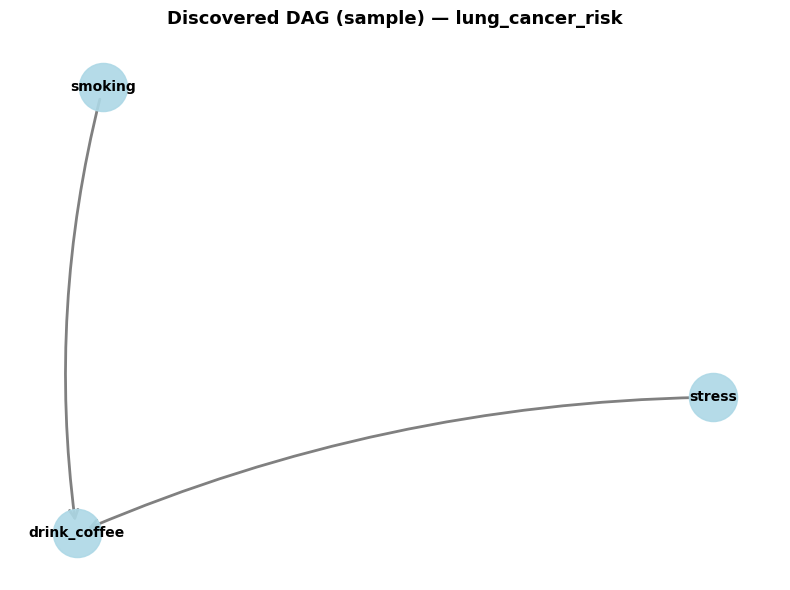

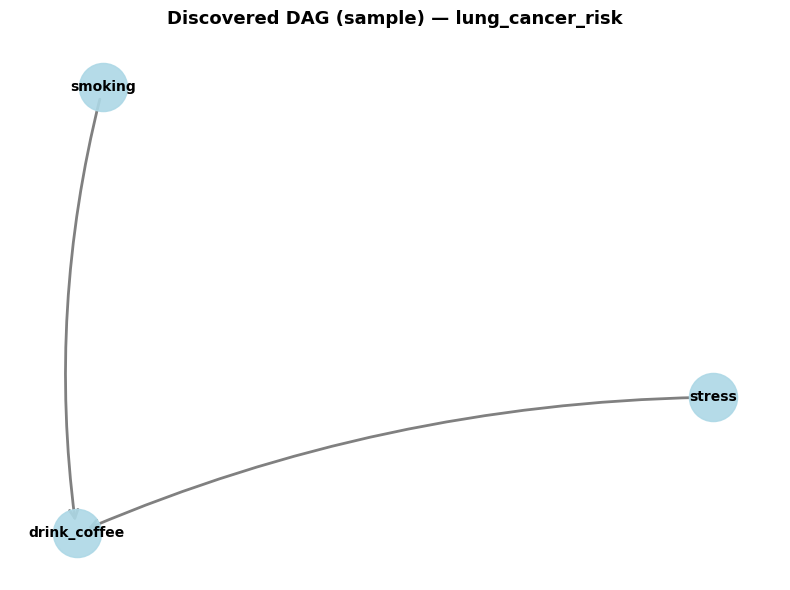

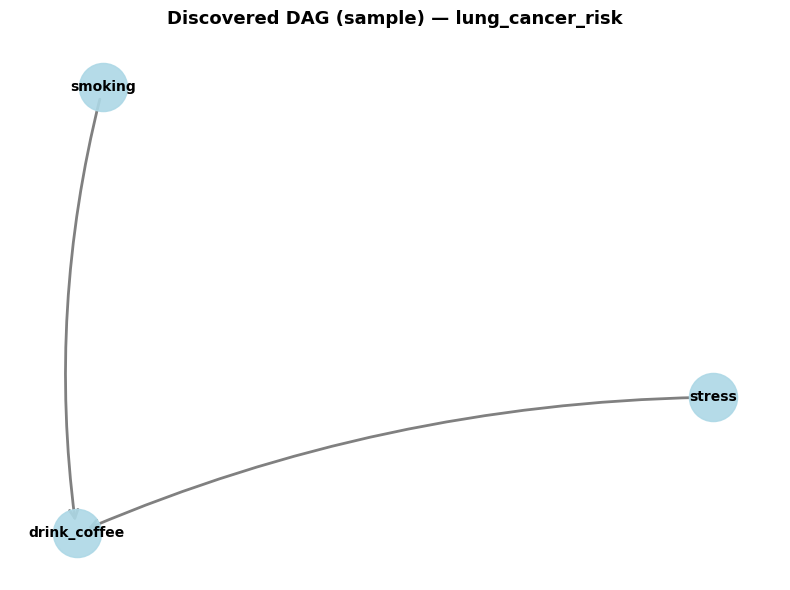

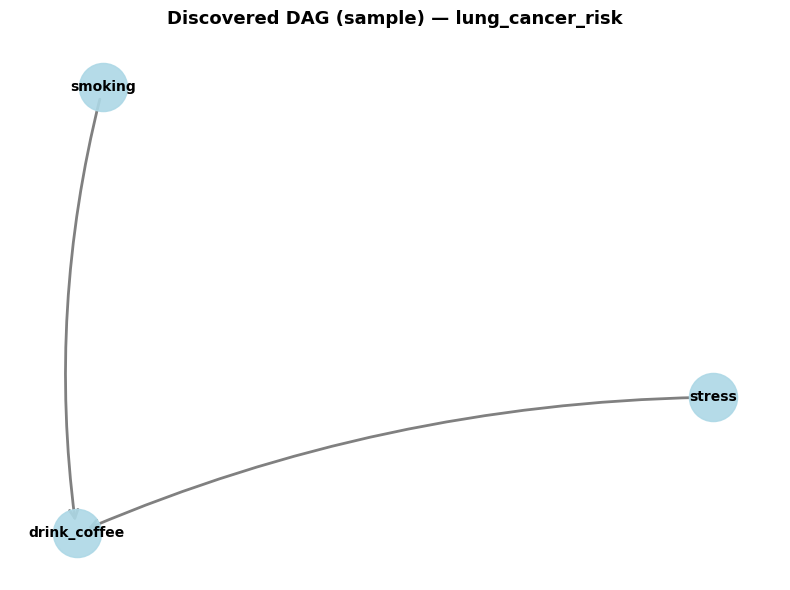

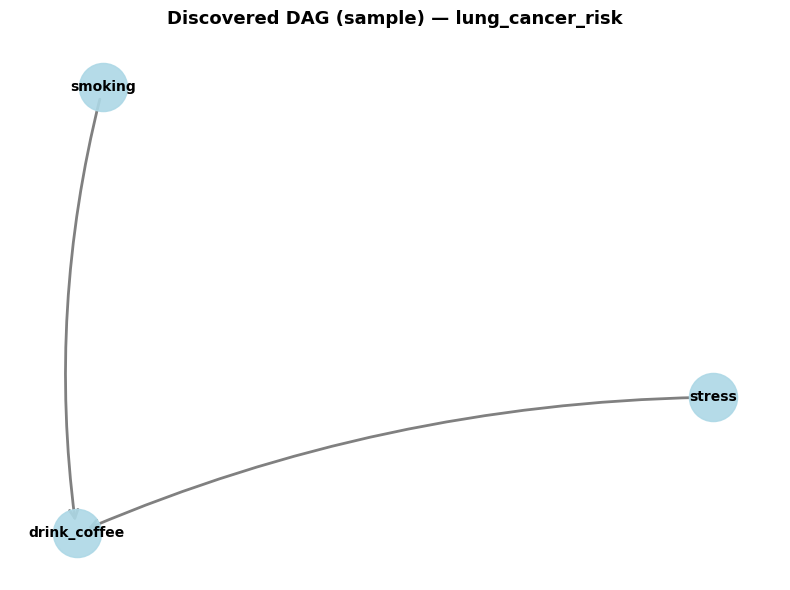

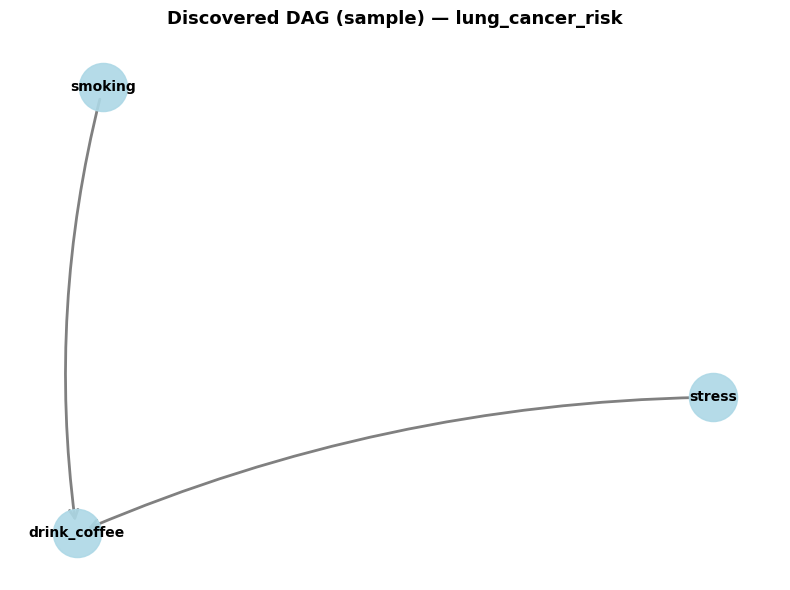

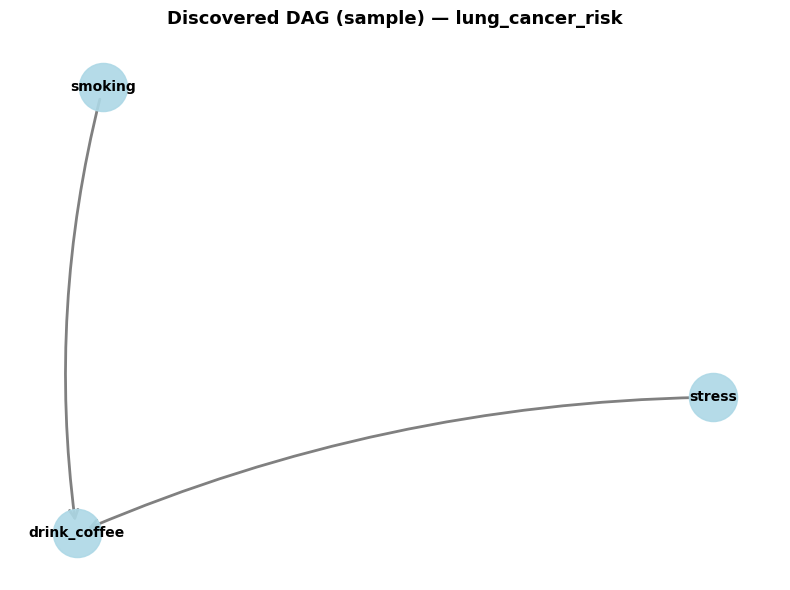

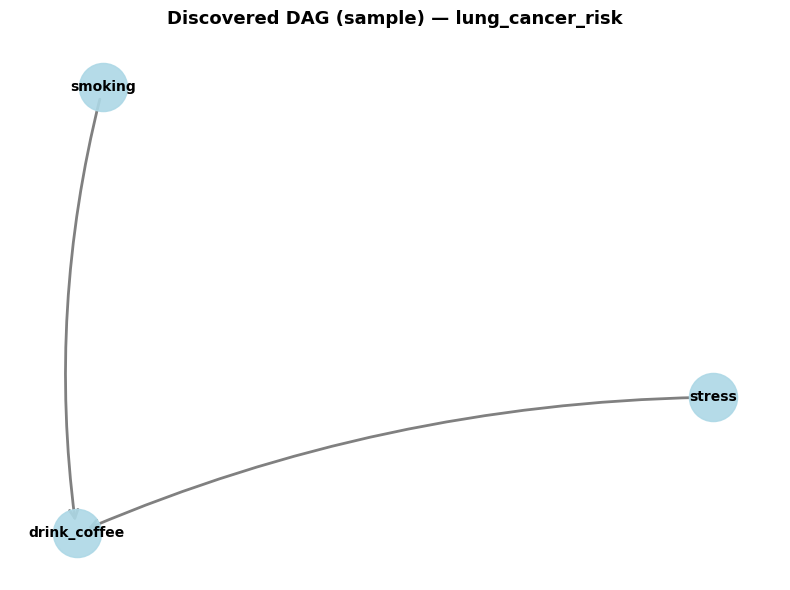

In [10]:
CSV_PATH = "../../datasets/lung_cancer_risk.csv"
TARGET_HINT = "lung_cancer_risk"  # optional

run_integrated_on_csv(CSV_PATH, dataset_name="lung_cancer_risk", target_hint=TARGET_HINT)

In [ ]:
#!/usr/bin/env python3

"""
Integrated Causal Discovery (PC) + Asymmetric Shapley Values (ASV)
- Discovers causal structure with PC (Causal SHAP methodology)
- Samples DAGs from CPDAG
- Computes ASV attributions using discovered DAG constraints

Research-ready: supports regression and classification; on-manifold value function.
"""

import os
import re
import random
import hashlib
from collections import defaultdict
from typing import Dict, List, Set, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, f1_score, r2_score, mean_absolute_error
from sklearn.utils.multiclass import type_of_target

# Causal discovery (PC)
from causallearn.search.ConstraintBased.PC import pc


RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

# Monte Carlo / sampling config
N_PERMUTATIONS_PER_POINT = 100     # permutations per instance (increase for higher fidelity)
N_MC_CONDITIONAL = 50              # E[f | x_S] samples
N_MC_UNCONDITIONAL = 200           # E[f] samples for v(∅)
K_NEIGHBORS = 20                   # K for conditional KNN
TEST_SIZE = 0.25
MAX_TEST_POINTS = 50               # limit for computational efficiency

# PC/graph sampling
PC_ALPHA = 0.1                     # independence test significance level
N_DAGS_FROM_CPDAG = 5              # number of DAG samples from CPDAG

# Output
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)


COMMON_TARGET_NAMES = [
    "target","label","y","class","outcome",
    "cvd","cardio","TenYearCHD","heart_disease","stroke","risk",
    "cancer","lung_cancer","has_cancer","diagnosis"
]

def detect_target_column(df: pd.DataFrame, user_hint: Optional[str]=None) -> str:
    if user_hint and user_hint in df.columns:
        return user_hint
    lower_map = {c.lower(): c for c in df.columns}
    for name in COMMON_TARGET_NAMES:
        if name.lower() in lower_map:
            return lower_map[name.lower()]
    return df.columns[-1]

def drop_unnamed_or_index_cols(df: pd.DataFrame) -> pd.DataFrame:
    drop_cols = []
    for c in df.columns:
        cl = str(c).strip().lower()
        if cl.startswith('unnamed') or cl in {'', 'index', 'id', 'x'}:
            drop_cols.append(c)
    if drop_cols:
        df = df.drop(columns=drop_cols)
    return df

def to_numeric_df(df: pd.DataFrame) -> pd.DataFrame:
    num = df.select_dtypes(include=[np.number]).copy()
    for c in df.columns:
        if c not in num.columns:
            try:
                num[c] = pd.to_numeric(df[c], errors='raise')
            except Exception:
                pass
    return num


class CausalStructure:
    def __init__(self, alpha: float = PC_ALPHA):
        self.alpha = alpha
        self.cpdag = None  # adjacency with -1/0/1 from causallearn
        self.feature_names: List[str] = []
        self.dags: List[nx.DiGraph] = []

    def discover(self, X: pd.DataFrame):
        self.feature_names = list(X.columns)
        print(f"Running PC on {len(self.feature_names)} features (alpha={self.alpha})...")
        res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = res.G.graph
        print("PC completed -> CPDAG")
        return self

    def sample_dags(self, n_samples: int = N_DAGS_FROM_CPDAG) -> List[nx.DiGraph]:
        rng = np.random.default_rng(RANDOM_SEED)
        dags: List[nx.DiGraph] = []
        names = self.feature_names
        n = len(names)

        # identify undirected edges (i<->j) in CPDAG
        undirected = []
        for i in range(n):
            for j in range(i+1, n):
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((names[i], names[j]))

        for _ in range(max(1, n_samples)):
            G = nx.DiGraph(); G.add_nodes_from(names)
            # add compelled directions (i -> j is (-1, 1))
            for i in range(n):
                for j in range(n):
                    if i != j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(names[i], names[j])
            # orient undirected edges randomly, ensure acyclicity
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)
                if not nx.is_directed_acyclic_graph(G):
                    # flip; if still cyclic remove
                    if G.has_edge(u, v):
                        G.remove_edge(u, v); G.add_edge(v, u)
                    else:
                        G.remove_edge(v, u); G.add_edge(u, v)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v)
                    if G.has_edge(v, u): G.remove_edge(v, u)
            if not nx.is_directed_acyclic_graph(G):
                for (a, b) in list(G.edges()):
                    G.remove_edge(a, b)
                    if nx.is_directed_acyclic_graph(G):
                        break
                    else:
                        G.add_edge(a, b)
            dags.append(G)
        self.dags = dags
        print(f"Sampled {len(dags)} DAG(s) from CPDAG")
        return dags


def plot_causal_graph(G: nx.DiGraph, title: str = "Discovered Causal Graph (PC)"):
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=RANDOM_SEED, k=1.0, iterations=200)
    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15, width=2,
                           arrowstyle='->', connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')
    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off'); plt.tight_layout()
    return plt.gcf()


class ConditionalKNNImputer:
    def __init__(self, X_train: np.ndarray, feature_names: List[str]):
        self.X_train = np.asarray(X_train)
        self.feature_names = feature_names
        self.n, self.d = self.X_train.shape
        self.scaler = StandardScaler().fit(self.X_train)
        self.Xs = self.scaler.transform(self.X_train)

    def sample_conditional(self, x: np.ndarray, S: Set[int], n_mc: int) -> np.ndarray:
        from sklearn.neighbors import NearestNeighbors
        x = np.asarray(x)
        if len(S) == 0:
            idx = np.random.randint(0, self.n, size=n_mc)
            return self.X_train[idx].copy()
        cols = sorted(list(S))
        Xs_S = self.Xs[:, cols]
        xS = self.scaler.transform(x.reshape(1, -1))[0, cols].reshape(1, -1)
        k = min(K_NEIGHBORS, self.n)
        nbrs = NearestNeighbors(n_neighbors=k, algorithm='auto', metric='euclidean')
        nbrs.fit(Xs_S)
        _, neigh_idx = nbrs.kneighbors(xS, return_distance=True)
        neigh_idx = neigh_idx[0]
        comp = [j for j in range(self.d) if j not in S]
        out = np.tile(x, (n_mc, 1))
        pick = np.random.choice(neigh_idx, size=n_mc, replace=True)
        out[:, comp] = self.X_train[pick][:, comp]
        return out


class OnManifoldValueFunction:
    def __init__(self, model, imputer: ConditionalKNNImputer, task_type: str = 'regression', y_true: Optional[int] = None):
        self.model = model
        self.imputer = imputer
        self.task_type = task_type
        self.y_true = y_true
        self.cache = {}

    def _cache_key(self, x: np.ndarray, S: Set[int], n_mc: int) -> str:
        x_hash = hashlib.sha256(np.asarray(x).tobytes()).hexdigest()[:16]
        return f"{x_hash}_{tuple(sorted(S))}_{n_mc}_{self.task_type}_{self.y_true}"

    def v_empty(self, n_mc: int = N_MC_UNCONDITIONAL) -> float:
        key = f"empty_{n_mc}_{self.task_type}_{self.y_true}"
        if key in self.cache:
            return self.cache[key]
        xs = self.imputer.sample_conditional(x=np.zeros(self.imputer.d), S=set(), n_mc=n_mc)
        if self.task_type == 'regression':
            pred = float(self.model.predict(xs).mean())
        else:
            proba = self.model.predict_proba(xs)
            if self.y_true is not None:
                pred = float(proba[:, self.y_true].mean())
            else:
                pred = float(proba.mean())
        self.cache[key] = pred
        return pred

    def v(self, x: np.ndarray, S: Set[int], n_mc: int = N_MC_CONDITIONAL) -> float:
        key = self._cache_key(x, S, n_mc)
        if key in self.cache:
            return self.cache[key]
        xs = self.imputer.sample_conditional(x, S, n_mc=n_mc)
        if self.task_type == 'regression':
            pred = float(self.model.predict(xs).mean())
        else:
            proba = self.model.predict_proba(xs)
            pred = float(proba[:, self.y_true].mean())
        self.cache[key] = pred
        return pred


def sample_topological_order_kahn(G: nx.DiGraph) -> List[str]:
    in_degree = {node: G.in_degree(node) for node in G.nodes()}
    queue = [node for node in G.nodes() if in_degree[node] == 0]
    order: List[str] = []
    while queue:
        random.shuffle(queue)
        node = queue.pop(0)
        order.append(node)
        for neighbor in G.neighbors(node):
            in_degree[neighbor] -= 1
            if in_degree[neighbor] == 0:
                queue.append(neighbor)
    if len(order) != len(G.nodes()):
        raise ValueError("Graph has cycles - cannot produce topological order")
    return order


def sample_orders_from_dags(dags: List[nx.DiGraph], n_samples: int) -> List[List[str]]:
    orders: List[List[str]] = []
    for _ in range(n_samples):
        G = random.choice(dags)
        orders.append(sample_topological_order_kahn(G))
    return orders


def efficiency_gap_local(phi: np.ndarray, vN: float, v0: float) -> float:
    return abs(phi.sum() - (vN - v0))


def local_asv_for_point(x: np.ndarray,
                        vfun: OnManifoldValueFunction,
                        feature_names: List[str],
                        dags: List[nx.DiGraph],
                        n_perms: int = N_PERMUTATIONS_PER_POINT) -> Tuple[np.ndarray, float, float]:
    d = len(feature_names)
    name_to_idx = {f: i for i, f in enumerate(feature_names)}
    perms_names = sample_orders_from_dags(dags, n_perms)
    perms_idx = [[name_to_idx[nm] for nm in perm] for perm in perms_names]
    v0 = vfun.v_empty()
    vN = vfun.v(x, set(range(d)))
    phi = np.zeros(d, dtype=float)
    for perm in perms_idx:
        S = set()
        prev = v0
        for j in perm:
            curr = vfun.v(x, S | {j})
            phi[j] += (curr - prev)
            prev = curr
            S.add(j)
    phi /= len(perms_idx)
    return phi, vN, v0


def train_model(X_train: np.ndarray, y_train: np.ndarray, task_type: str):
    if task_type == 'regression':
        model = RandomForestRegressor(
            n_estimators=200,
            max_depth=6,
            max_features='sqrt',
            random_state=RANDOM_SEED,
            n_jobs=-1
        )
    else:
        model = RandomForestClassifier(
            n_estimators=200,
            max_depth=6,
            max_features='sqrt',
            random_state=RANDOM_SEED,
            n_jobs=-1
        )
    model.fit(X_train, y_train)
    return model


def run_integrated_on_csv(csv_path: str,
                          dataset_name: Optional[str] = None,
                          target_hint: Optional[str] = None,
                          test_size: float = TEST_SIZE,
                          max_eval_points: int = MAX_TEST_POINTS):
    print("\n" + "="*80)
    print(f"Integrated Causal Discovery + ASV on: {csv_path}")
    print("="*80)

    df = pd.read_csv(csv_path)
    df = drop_unnamed_or_index_cols(df)

    if dataset_name is None:
        dataset_name = os.path.splitext(os.path.basename(csv_path))[0]

    tgt_col = detect_target_column(df, target_hint)
    assert tgt_col in df.columns, f"Target '{tgt_col}' not found in CSV"

    y_raw = df[tgt_col].copy()
    X_raw = df.drop(columns=[tgt_col])

    X_num = to_numeric_df(X_raw)
    dropped = set(X_raw.columns) - set(X_num.columns)
    if dropped:
        print(f"Note: Dropping non-numeric columns: {sorted(list(dropped))}")

    X_num = X_num.replace([np.inf, -np.inf], np.nan)
    X_num = X_num.fillna(X_num.median(numeric_only=True))

    y_type = type_of_target(y_raw)
    if y_type in ["binary", "multiclass"]:
        task_type = 'classification'
        y_vec = y_raw.astype(int).values
    else:
        task_type = 'regression'
        y_vec = pd.to_numeric(y_raw, errors='coerce').values.astype(float)
        if np.isnan(y_vec).any():
            raise ValueError("Target has non-numeric values that cannot be coerced")

    strat = y_vec if (task_type == 'classification' and len(np.unique(y_vec)) > 1) else None
    X_train_df, X_test_df, y_train, y_test = train_test_split(
        X_num, y_vec, test_size=test_size, random_state=RANDOM_SEED, stratify=strat
    )

    # scale features
    scaler = StandardScaler()
    Xtr = pd.DataFrame(scaler.fit_transform(X_train_df), columns=X_train_df.columns, index=X_train_df.index)
    Xte = pd.DataFrame(scaler.transform(X_test_df),  columns=X_test_df.columns,  index=X_test_df.index)

    # train model
    print("\nTraining model...")
    model = train_model(Xtr.values, y_train, task_type)
    if task_type == 'classification':
        y_pred = model.predict(Xte.values)
        acc = accuracy_score(y_test, y_pred)
        f1m = f1_score(y_test, y_pred, average='macro')
        print(f"Model: acc={acc:.4f}, macroF1={f1m:.4f}")
    else:
        y_pred = model.predict(Xte.values)
        r2 = r2_score(y_test, y_pred)
        mae = mean_absolute_error(y_test, y_pred)
        print(f"Model: R2={r2:.4f}, MAE={mae:.4f}")

    # Causal discovery on training set
    print("\n" + "-"*72)
    print("Step 1: Causal discovery (PC)")
    print("-"*72)
    cs = CausalStructure(alpha=PC_ALPHA).discover(Xtr)
    dags = cs.sample_dags(N_DAGS_FROM_CPDAG)

    # visualize one sampled DAG (skeleton orientation)
    G_show = dags[0]
    fig = plot_causal_graph(G_show, title=f"Discovered DAG (sample) — {dataset_name}")
    fig.savefig(os.path.join(OUT_DIR, f"causal_graph_sample_{dataset_name}.png"), dpi=150, bbox_inches='tight')
    print(f"Saved '{os.path.join(OUT_DIR, f'causal_graph_sample_{dataset_name}.png')}'")

    # On-manifold imputer
    print("\nInitializing on-manifold imputer...")
    imputer_conditional = ConditionalKNNImputer(Xtr.values, list(Xtr.columns))

    # Subsample test points
    n_eval = min(max_eval_points, len(Xte))
    if len(Xte) > n_eval:
        idx = np.random.choice(len(Xte), size=n_eval, replace=False)
        X_eval = Xte.values[idx]
        y_eval = y_test[idx]
    else:
        X_eval = Xte.values
        y_eval = y_test

    print(f"\nEvaluating ASV on {len(X_eval)} test points...")

    feature_names = list(Xtr.columns)
    d = len(feature_names)
    asv_vals = []
    eff_gaps = []

    for i, (x, y_true) in enumerate(zip(X_eval, y_eval)):
        if i % 10 == 0:
            print(f"  Processing point {i+1}/{len(X_eval)}")
        vfun = OnManifoldValueFunction(
            model, imputer_conditional, task_type,
            y_true=int(y_true) if task_type == 'classification' else None
        )
        phi_asv, vN, v0 = local_asv_for_point(x, vfun, feature_names, dags)
        asv_vals.append(phi_asv)
        eff_gaps.append(efficiency_gap_local(phi_asv, vN, v0))

    asv_vals = np.vstack(asv_vals)
    global_asv = asv_vals.mean(axis=0)
    global_asv_std = asv_vals.std(axis=0)

    print("\nEfficiency verification (mean |sum(phi) - (vN - v0)|):")
    print(f"  Mean gap (ASV): {np.mean(eff_gaps):.6f}")

    # Save results
    out_csv = os.path.join(OUT_DIR, f"{dataset_name}_global_asv_onmanifold_causal.csv")
    pd.DataFrame({
        'feature': feature_names,
        'global_value': global_asv,
        'std': global_asv_std
    }).to_csv(out_csv, index=False)
    print(f"Saved: {out_csv}")

    # Plot bar chart
    fig, ax = plt.subplots(figsize=(10, 6))
    order = np.argsort(global_asv)[::-1]
    colors = ['#1f77b4' if v >= 0 else '#d62728' for v in global_asv[order]]
    ax.bar(range(d), global_asv[order], yerr=global_asv_std[order], capsize=4, color=colors, alpha=0.9, edgecolor='black', linewidth=0.8)
    ax.set_xticks(range(d))
    ax.set_xticklabels(np.array(feature_names)[order], rotation=45, ha='right')
    ax.set_ylabel("Global ASV (on-manifold)")
    ax.set_title(f"ASV with Causal Discovery — {dataset_name}")
    ax.axhline(y=0, color='black', linewidth=1.0)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    out_png = os.path.join(OUT_DIR, f"{dataset_name}_asv_onmanifold_causal.png")
    plt.savefig(out_png, dpi=150, bbox_inches='tight', facecolor='white')
    plt.close()
    print(f"Saved: {out_png}")

    # Console summary
    print("\nTop features (ASV on-manifold, causal):")
    for i in np.argsort(global_asv)[::-1][:10]:
        print(f"  {feature_names[i]:25s} {global_asv[i]:+.6f} ± {global_asv_std[i]:.6f}")

    print("\n" + "="*80)
    print("Done.")

In [19]:
#!/usr/bin/env python3

"""
Integrated Causal Discovery (PC) + Asymmetric Shapley Values (ASV)
- Discovers causal structure with PC (Causal SHAP methodology)
- Samples DAGs from CPDAG
- Computes ASV attributions using discovered DAG constraints

Research-ready: supports regression and classification; on-manifold value function.
"""

import os
import re
import random
import hashlib
from collections import defaultdict
from typing import Dict, List, Set, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, f1_score, r2_score, mean_absolute_error
from sklearn.utils.multiclass import type_of_target

# Causal discovery (PC)
from causallearn.search.ConstraintBased.PC import pc


RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

# Monte Carlo / sampling config
N_PERMUTATIONS_PER_POINT = 100     # permutations per instance (increase for higher fidelity)
N_MC_CONDITIONAL = 50              # E[f | x_S] samples
N_MC_UNCONDITIONAL = 200           # E[f] samples for v(∅)
K_NEIGHBORS = 20                   # K for conditional KNN
TEST_SIZE = 0.25
MAX_TEST_POINTS = 50               # limit for computational efficiency

# PC/graph sampling
PC_ALPHA = 0.1                     # independence test significance level
N_DAGS_FROM_CPDAG = 5              # number of DAG samples from CPDAG

# Output
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)


COMMON_TARGET_NAMES = [
    "target","label","y","class","outcome",
    "cvd","cardio","TenYearCHD","heart_disease","stroke","risk",
    "cancer","lung_cancer","has_cancer","diagnosis"
]

def detect_target_column(df: pd.DataFrame, user_hint: Optional[str]=None) -> str:
    if user_hint and user_hint in df.columns:
        return user_hint
    lower_map = {c.lower(): c for c in df.columns}
    for name in COMMON_TARGET_NAMES:
        if name.lower() in lower_map:
            return lower_map[name.lower()]
    return df.columns[-1]

def drop_unnamed_or_index_cols(df: pd.DataFrame) -> pd.DataFrame:
    drop_cols = []
    for c in df.columns:
        cl = str(c).strip().lower()
        if cl.startswith('unnamed') or cl in {'', 'index', 'id', 'x'}:
            drop_cols.append(c)
    if drop_cols:
        df = df.drop(columns=drop_cols)
    return df

def to_numeric_df(df: pd.DataFrame) -> pd.DataFrame:
    num = df.select_dtypes(include=[np.number]).copy()
    for c in df.columns:
        if c not in num.columns:
            try:
                num[c] = pd.to_numeric(df[c], errors='raise')
            except Exception:
                pass
    return num


class CausalStructure:
    def __init__(self, alpha: float = PC_ALPHA):
        self.alpha = alpha
        self.cpdag = None  # adjacency with -1/0/1 from causallearn
        self.feature_names: List[str] = []
        self.dags: List[nx.DiGraph] = []

    def discover(self, X: pd.DataFrame):
        self.feature_names = list(X.columns)
        print(f"Running PC on {len(self.feature_names)} features (alpha={self.alpha})...")
        res = pc(X.values, alpha=self.alpha, show_progress=False)
        self.cpdag = res.G.graph
        print("PC completed -> CPDAG")
        return self

    def sample_dags(self, n_samples: int = N_DAGS_FROM_CPDAG) -> List[nx.DiGraph]:
        rng = np.random.default_rng(RANDOM_SEED)
        dags: List[nx.DiGraph] = []
        names = self.feature_names
        n = len(names)

        # identify undirected edges (i<->j) in CPDAG
        undirected = []
        for i in range(n):
            for j in range(i+1, n):
                if self.cpdag[i, j] == -1 and self.cpdag[j, i] == -1:
                    undirected.append((names[i], names[j]))

        for _ in range(max(1, n_samples)):
            G = nx.DiGraph(); G.add_nodes_from(names)
            # add compelled directions (i -> j is (-1, 1))
            for i in range(n):
                for j in range(n):
                    if i != j and self.cpdag[i, j] == -1 and self.cpdag[j, i] == 1:
                        G.add_edge(names[i], names[j])
            # orient undirected edges randomly, ensure acyclicity
            for u, v in undirected:
                if rng.random() < 0.5:
                    G.add_edge(u, v)
                else:
                    G.add_edge(v, u)
                if not nx.is_directed_acyclic_graph(G):
                    # flip; if still cyclic remove
                    if G.has_edge(u, v):
                        G.remove_edge(u, v); G.add_edge(v, u)
                    else:
                        G.remove_edge(v, u); G.add_edge(u, v)
                if not nx.is_directed_acyclic_graph(G):
                    if G.has_edge(u, v): G.remove_edge(u, v)
                    if G.has_edge(v, u): G.remove_edge(v, u)
            if not nx.is_directed_acyclic_graph(G):
                for (a, b) in list(G.edges()):
                    G.remove_edge(a, b)
                    if nx.is_directed_acyclic_graph(G):
                        break
                    else:
                        G.add_edge(a, b)
            dags.append(G)
        self.dags = dags
        print(f"Sampled {len(dags)} DAG(s) from CPDAG")
        return dags


def plot_causal_graph(G: nx.DiGraph, title: str = "Discovered Causal Graph (PC)"):
    plt.figure(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=RANDOM_SEED, k=1.0, iterations=200)
    nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=1200, alpha=0.9)
    nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=15, width=2,
                           arrowstyle='->', connectionstyle='arc3,rad=0.1')
    nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')
    plt.title(title, fontsize=13, fontweight='bold', pad=12)
    plt.axis('off'); plt.tight_layout()
    return plt.gcf()


class ConditionalKNNImputer:
    def __init__(self, X_train: np.ndarray, feature_names: List[str]):
        self.X_train = np.asarray(X_train)
        self.feature_names = feature_names
        self.n, self.d = self.X_train.shape
        self.scaler = StandardScaler().fit(self.X_train)
        self.Xs = self.scaler.transform(self.X_train)

    def sample_conditional(self, x: np.ndarray, S: Set[int], n_mc: int) -> np.ndarray:
        from sklearn.neighbors import NearestNeighbors
        x = np.asarray(x)
        if len(S) == 0:
            idx = np.random.randint(0, self.n, size=n_mc)
            return self.X_train[idx].copy()
        cols = sorted(list(S))
        Xs_S = self.Xs[:, cols]
        xS = self.scaler.transform(x.reshape(1, -1))[0, cols].reshape(1, -1)
        k = min(K_NEIGHBORS, self.n)
        nbrs = NearestNeighbors(n_neighbors=k, algorithm='auto', metric='euclidean')
        nbrs.fit(Xs_S)
        _, neigh_idx = nbrs.kneighbors(xS, return_distance=True)
        neigh_idx = neigh_idx[0]
        comp = [j for j in range(self.d) if j not in S]
        out = np.tile(x, (n_mc, 1))
        pick = np.random.choice(neigh_idx, size=n_mc, replace=True)
        out[:, comp] = self.X_train[pick][:, comp]
        return out


class OnManifoldValueFunction:
    def __init__(self, model, imputer: ConditionalKNNImputer, task_type: str = 'regression', y_true: Optional[int] = None):
        self.model = model
        self.imputer = imputer
        self.task_type = task_type
        self.y_true = y_true
        self.cache = {}

    def _cache_key(self, x: np.ndarray, S: Set[int], n_mc: int) -> str:
        x_hash = hashlib.sha256(np.asarray(x).tobytes()).hexdigest()[:16]
        return f"{x_hash}_{tuple(sorted(S))}_{n_mc}_{self.task_type}_{self.y_true}"

    def v_empty(self, n_mc: int = N_MC_UNCONDITIONAL) -> float:
        key = f"empty_{n_mc}_{self.task_type}_{self.y_true}"
        if key in self.cache:
            return self.cache[key]
        xs = self.imputer.sample_conditional(x=np.zeros(self.imputer.d), S=set(), n_mc=n_mc)
        if self.task_type == 'regression':
            pred = float(self.model.predict(xs).mean())
        else:
            proba = self.model.predict_proba(xs)
            if self.y_true is not None:
                pred = float(proba[:, self.y_true].mean())
            else:
                pred = float(proba.mean())
        self.cache[key] = pred
        return pred

    def v(self, x: np.ndarray, S: Set[int], n_mc: int = N_MC_CONDITIONAL) -> float:
        key = self._cache_key(x, S, n_mc)
        if key in self.cache:
            return self.cache[key]
        xs = self.imputer.sample_conditional(x, S, n_mc=n_mc)
        if self.task_type == 'regression':
            pred = float(self.model.predict(xs).mean())
        else:
            proba = self.model.predict_proba(xs)
            pred = float(proba[:, self.y_true].mean())
        self.cache[key] = pred
        return pred


def sample_topological_order_kahn(G: nx.DiGraph) -> List[str]:
    in_degree = {node: G.in_degree(node) for node in G.nodes()}
    queue = [node for node in G.nodes() if in_degree[node] == 0]
    order: List[str] = []
    while queue:
        random.shuffle(queue)
        node = queue.pop(0)
        order.append(node)
        for neighbor in G.neighbors(node):
            in_degree[neighbor] -= 1
            if in_degree[neighbor] == 0:
                queue.append(neighbor)
    if len(order) != len(G.nodes()):
        raise ValueError("Graph has cycles - cannot produce topological order")
    return order


def sample_orders_from_dags(dags: List[nx.DiGraph], n_samples: int) -> List[List[str]]:
    orders: List[List[str]] = []
    for _ in range(n_samples):
        G = random.choice(dags)
        orders.append(sample_topological_order_kahn(G))
    return orders


def efficiency_gap_local(phi: np.ndarray, vN: float, v0: float) -> float:
    return abs(phi.sum() - (vN - v0))


def local_asv_for_point(x: np.ndarray,
                        vfun: OnManifoldValueFunction,
                        feature_names: List[str],
                        dags: List[nx.DiGraph],
                        n_perms: int = N_PERMUTATIONS_PER_POINT) -> Tuple[np.ndarray, float, float]:
    d = len(feature_names)
    name_to_idx = {f: i for i, f in enumerate(feature_names)}
    perms_names = sample_orders_from_dags(dags, n_perms)
    perms_idx = [[name_to_idx[nm] for nm in perm] for perm in perms_names]
    v0 = vfun.v_empty()
    vN = vfun.v(x, set(range(d)))
    phi = np.zeros(d, dtype=float)
    for perm in perms_idx:
        S = set()
        prev = v0
        for j in perm:
            curr = vfun.v(x, S | {j})
            phi[j] += (curr - prev)
            prev = curr
            S.add(j)
    phi /= len(perms_idx)
    return phi, vN, v0


def train_model(X_train: np.ndarray, y_train: np.ndarray, task_type: str):
    if task_type == 'regression':
        model = RandomForestRegressor(
            n_estimators=200,
            max_depth=6,
            max_features='sqrt',
            random_state=RANDOM_SEED,
            n_jobs=-1
        )
    else:
        model = RandomForestClassifier(
            n_estimators=200,
            max_depth=6,
            max_features='sqrt',
            random_state=RANDOM_SEED,
            n_jobs=-1
        )
    model.fit(X_train, y_train)
    return model


def run_integrated_on_csv(csv_path: str,
                          dataset_name: Optional[str] = None,
                          target_hint: Optional[str] = None,
                          test_size: float = TEST_SIZE,
                          max_eval_points: int = MAX_TEST_POINTS,
                          seed: int = RANDOM_SEED):
    # Ensure determinism per run
    np.random.seed(seed)
    random.seed(seed)

    print("\n" + "="*80)
    print(f"Integrated Causal Discovery + ASV on: {csv_path}")
    print("="*80)

    df = pd.read_csv(csv_path)
    df = drop_unnamed_or_index_cols(df)

    if dataset_name is None:
        dataset_name = os.path.splitext(os.path.basename(csv_path))[0]

    tgt_col = detect_target_column(df, target_hint)
    assert tgt_col in df.columns, f"Target '{tgt_col}' not found in CSV"

    y_raw = df[tgt_col].copy()
    X_raw = df.drop(columns=[tgt_col])

    X_num = to_numeric_df(X_raw)
    dropped = set(X_raw.columns) - set(X_num.columns)
    if dropped:
        print(f"Note: Dropping non-numeric columns: {sorted(list(dropped))}")

    X_num = X_num.replace([np.inf, -np.inf], np.nan)
    X_num = X_num.fillna(X_num.median(numeric_only=True))

    y_type = type_of_target(y_raw)
    if y_type in ["binary", "multiclass"]:
        task_type = 'classification'
        # Handle both numeric and string labels
        if pd.api.types.is_numeric_dtype(y_raw):
            y_vec = y_raw.astype(int).values
        else:
            codes, uniques = pd.factorize(y_raw.astype(str))
            y_vec = codes.astype(int)
            print(f"Label mapping: {dict(enumerate(uniques.tolist()))}")
    else:
        task_type = 'regression'
        y_vec = pd.to_numeric(y_raw, errors='coerce').values.astype(float)
        if np.isnan(y_vec).any():
            raise ValueError("Target has non-numeric values that cannot be coerced")

    strat = y_vec if (task_type == 'classification' and len(np.unique(y_vec)) > 1) else None
    X_train_df, X_test_df, y_train, y_test = train_test_split(
        X_num, y_vec, test_size=test_size, random_state=RANDOM_SEED, stratify=strat
    )

    # scale features
    scaler = StandardScaler()
    Xtr = pd.DataFrame(scaler.fit_transform(X_train_df), columns=X_train_df.columns, index=X_train_df.index)
    Xte = pd.DataFrame(scaler.transform(X_test_df),  columns=X_test_df.columns,  index=X_test_df.index)

    # train model
    print("\nTraining model...")
    model = train_model(Xtr.values, y_train, task_type)
    if task_type == 'classification':
        y_pred = model.predict(Xte.values)
        acc = accuracy_score(y_test, y_pred)
        f1m = f1_score(y_test, y_pred, average='macro')
        print(f"Model: acc={acc:.4f}, macroF1={f1m:.4f}")
    else:
        y_pred = model.predict(Xte.values)
        r2 = r2_score(y_test, y_pred)
        mae = mean_absolute_error(y_test, y_pred)
        print(f"Model: R2={r2:.4f}, MAE={mae:.4f}")

    # Causal discovery on training set
    print("\n" + "-"*72)
    print("Step 1: Causal discovery (PC)")
    print("-"*72)
    cs = CausalStructure(alpha=PC_ALPHA).discover(Xtr)
    dags = cs.sample_dags(N_DAGS_FROM_CPDAG)

    # visualize one sampled DAG (skeleton orientation)
    G_show = dags[0]
    fig = plot_causal_graph(G_show, title=f"Discovered DAG (sample) — {dataset_name}")
    fig.savefig(os.path.join(OUT_DIR, f"causal_graph_sample_{dataset_name}.png"), dpi=150, bbox_inches='tight')
    print(f"Saved '{os.path.join(OUT_DIR, f'causal_graph_sample_{dataset_name}.png')}'")

    # On-manifold imputer
    print("\nInitializing on-manifold imputer...")
    imputer_conditional = ConditionalKNNImputer(Xtr.values, list(Xtr.columns))

    # Subsample test points
    n_eval = min(max_eval_points, len(Xte))
    if len(Xte) > n_eval:
        idx = np.random.choice(len(Xte), size=n_eval, replace=False)
        X_eval = Xte.values[idx]
        y_eval = y_test[idx]
    else:
        X_eval = Xte.values
        y_eval = y_test

    print(f"\nEvaluating ASV on {len(X_eval)} test points...")

    feature_names = list(Xtr.columns)
    d = len(feature_names)
    asv_vals = []
    eff_gaps = []

    for i, (x, y_true) in enumerate(zip(X_eval, y_eval)):
        if i % 10 == 0:
            print(f"  Processing point {i+1}/{len(X_eval)}")
        vfun = OnManifoldValueFunction(
            model, imputer_conditional, task_type,
            y_true=int(y_true) if task_type == 'classification' else None
        )
        phi_asv, vN, v0 = local_asv_for_point(x, vfun, feature_names, dags)
        asv_vals.append(phi_asv)
        eff_gaps.append(efficiency_gap_local(phi_asv, vN, v0))

    asv_vals = np.vstack(asv_vals)
    global_asv = asv_vals.mean(axis=0)
    global_asv_std = asv_vals.std(axis=0)

    print("\nEfficiency verification (mean |sum(phi) - (vN - v0)|):")
    print(f"  Mean gap (ASV): {np.mean(eff_gaps):.6f}")

    # Save results
    out_csv = os.path.join(OUT_DIR, f"{dataset_name}_global_asv_onmanifold_causal.csv")
    pd.DataFrame({
        'feature': feature_names,
        'global_value': global_asv,
        'std': global_asv_std
    }).to_csv(out_csv, index=False)
    print(f"Saved: {out_csv}")

    # Plot bar chart
    fig, ax = plt.subplots(figsize=(10, 6))
    order = np.argsort(global_asv)[::-1]
    colors = ['#1f77b4' if v >= 0 else '#d62728' for v in global_asv[order]]
    ax.bar(range(d), global_asv[order], yerr=global_asv_std[order], capsize=4, color=colors, alpha=0.9, edgecolor='black', linewidth=0.8)
    ax.set_xticks(range(d))
    ax.set_xticklabels(np.array(feature_names)[order], rotation=45, ha='right')
    ax.set_ylabel("Global ASV (on-manifold)")
    ax.set_title(f"ASV with Causal Discovery — {dataset_name}")
    ax.axhline(y=0, color='black', linewidth=1.0)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    out_png = os.path.join(OUT_DIR, f"{dataset_name}_asv_onmanifold_causal.png")
    plt.savefig(out_png, dpi=150, bbox_inches='tight', facecolor='white')
    plt.close()
    print(f"Saved: {out_png}")

    # Console summary
    print("\nTop features (ASV on-manifold, causal):")
    for i in np.argsort(global_asv)[::-1][:10]:
        print(f"  {feature_names[i]:25s} {global_asv[i]:+.6f} ± {global_asv_std[i]:.6f}")

    print("\n" + "="*80)
    print("Done.")

In [20]:
def _infer_task_type_from_y(y: np.ndarray) -> str:
    y = np.asarray(y).ravel()
    # if all finite integers and small number of classes => classification
    if np.all(np.isfinite(y)) and np.all(np.equal(y, y.astype(int))):
        return 'classification'
    return 'regression'


def run_integrated_on_numpy_bundle(path: str,
                                   dataset_name: Optional[str] = None,
                                   task_type: Optional[str] = None,
                                   seed: int = RANDOM_SEED,
                                   max_eval_points: int = MAX_TEST_POINTS):
    """
    Run end-to-end on a NumPy bundle. Accepts either:
      - .npz file with keys: X_train, X_test, y_train, y_test, feature_names
      - directory containing the files: X_train.npy, X_test.npy, y_train.npy, y_test.npy, feature_names.npy
    """
    # Ensure determinism per run
    np.random.seed(seed)
    random.seed(seed)

    if path.endswith('.npz'):
        data = np.load(path, allow_pickle=True)
        X_train = np.asarray(data['X_train'])
        X_test = np.asarray(data['X_test'])
        y_train = np.asarray(data['y_train']).ravel()
        y_test = np.asarray(data['y_test']).ravel()
        feature_names = list(np.array(data['feature_names']).astype(str))
        if dataset_name is None:
            dataset_name = os.path.splitext(os.path.basename(path))[0]
    else:
        base = path
        X_train = np.load(os.path.join(base, 'X_train.npy'))
        X_test = np.load(os.path.join(base, 'X_test.npy'))
        y_train = np.load(os.path.join(base, 'y_train.npy')).ravel()
        y_test = np.load(os.path.join(base, 'y_test.npy')).ravel()
        feature_names = list(np.load(os.path.join(base, 'feature_names.npy')).astype(str))
        if dataset_name is None:
            dataset_name = os.path.basename(os.path.normpath(base))

    if task_type is None:
        task_type = _infer_task_type_from_y(y_train)

    print("\n" + "="*80)
    print(f"Integrated Causal Discovery + ASV on NumPy bundle: {path}")
    print(f"Task type: {task_type}")
    print("="*80)

    # Scale features using training set
    scaler = StandardScaler().fit(X_train)
    Xtr = scaler.transform(X_train)
    Xte = scaler.transform(X_test)

    # Train model
    print("\nTraining model...")
    model = train_model(Xtr, y_train, task_type)
    if task_type == 'classification':
        y_pred = model.predict(Xte)
        acc = accuracy_score(y_test, y_pred)
        f1m = f1_score(y_test, y_pred, average='macro')
        print(f"Model: acc={acc:.4f}, macroF1={f1m:.4f}")
    else:
        y_pred = model.predict(Xte)
        r2 = r2_score(y_test, y_pred)
        mae = mean_absolute_error(y_test, y_pred)
        print(f"Model: R2={r2:.4f}, MAE={mae:.4f}")

    # Causal discovery on training set (use DataFrame to carry names)
    Xtr_df = pd.DataFrame(Xtr, columns=feature_names)
    print("\n" + "-"*72)
    print("Step 1: Causal discovery (PC)")
    print("-"*72)
    cs = CausalStructure(alpha=PC_ALPHA).discover(Xtr_df)
    dags = cs.sample_dags(N_DAGS_FROM_CPDAG)

    # Visualize a sampled DAG
    G_show = dags[0]
    fig = plot_causal_graph(G_show, title=f"Discovered DAG (sample) — {dataset_name}")
    fig.savefig(os.path.join(OUT_DIR, f"causal_graph_sample_{dataset_name}.png"), dpi=150, bbox_inches='tight')
    print(f"Saved '{os.path.join(OUT_DIR, f'causal_graph_sample_{dataset_name}.png')}'")

    # On-manifold imputer on training set
    imputer_conditional = ConditionalKNNImputer(Xtr, feature_names)

    # Subsample evaluation points
    n_eval = min(max_eval_points, len(Xte))
    if len(Xte) > n_eval:
        idx = np.random.choice(len(Xte), size=n_eval, replace=False)
        X_eval = Xte[idx]
        y_eval = y_test[idx]
    else:
        X_eval = Xte
        y_eval = y_test

    print(f"\nEvaluating ASV on {len(X_eval)} test points...")

    d = len(feature_names)
    asv_vals = []
    eff_gaps = []

    for i, (x, y_true) in enumerate(zip(X_eval, y_eval)):
        if i % 10 == 0:
            print(f"  Processing point {i+1}/{len(X_eval)}")
        vfun = OnManifoldValueFunction(
            model, imputer_conditional, task_type,
            y_true=int(y_true) if task_type == 'classification' else None
        )
        phi_asv, vN, v0 = local_asv_for_point(x, vfun, feature_names, dags)
        asv_vals.append(phi_asv)
        eff_gaps.append(efficiency_gap_local(phi_asv, vN, v0))

    asv_vals = np.vstack(asv_vals)
    global_asv = asv_vals.mean(axis=0)
    global_asv_std = asv_vals.std(axis=0)

    print("\nEfficiency verification (mean |sum(phi) - (vN - v0)|):")
    print(f"  Mean gap (ASV): {np.mean(eff_gaps):.6f}")

    out_csv = os.path.join(OUT_DIR, f"{dataset_name}_global_asv_onmanifold_causal.csv")
    pd.DataFrame({'feature': feature_names, 'global_value': global_asv, 'std': global_asv_std}).to_csv(out_csv, index=False)
    print(f"Saved: {out_csv}")

    fig, ax = plt.subplots(figsize=(10, 6))
    order = np.argsort(global_asv)[::-1]
    colors = ['#1f77b4' if v >= 0 else '#d62728' for v in global_asv[order]]
    ax.bar(range(d), global_asv[order], yerr=global_asv_std[order], capsize=4, color=colors, alpha=0.9, edgecolor='black', linewidth=0.8)
    ax.set_xticks(range(d))
    ax.set_xticklabels(np.array(feature_names)[order], rotation=45, ha='right')
    ax.set_ylabel("Global ASV (on-manifold)")
    ax.set_title(f"ASV with Causal Discovery — {dataset_name}")
    ax.axhline(y=0, color='black', linewidth=1.0)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    plt.tight_layout()
    out_png = os.path.join(OUT_DIR, f"{dataset_name}_asv_onmanifold_causal.png")
    plt.savefig(out_png, dpi=150, bbox_inches='tight', facecolor='white'); plt.close()
    print(f"Saved: {out_png}")

    print("\nTop features (ASV on-manifold, causal):")
    for i in np.argsort(global_asv)[::-1][:10]:
        print(f"  {feature_names[i]:25s} {global_asv[i]:+.6f} ± {global_asv_std[i]:.6f}")

    print("\n" + "="*80)
    print("Done.")


Integrated Causal Discovery + ASV on NumPy bundle: ../datasets/yield_preprocessed.npz
Task type: classification

Training model...
✓ Model: acc=0.8300, macroF1=0.8330

------------------------------------------------------------------------
Step 1: Causal discovery (PC)
------------------------------------------------------------------------
Running PC on 4 features (alpha=0.1)...
✓ PC completed -> CPDAG
✓ Sampled 5 DAG(s) from CPDAG
✓ Saved 'outputs/causal_graph_sample_yield.png'

Evaluating ASV on 50 test points...
  Processing point 1/50
  Processing point 11/50
  Processing point 21/50
  Processing point 31/50
  Processing point 41/50

Efficiency verification (mean |sum(phi) - (vN - v0)|):
  Mean gap (ASV): 0.000000
Saved: outputs/yield_global_asv_onmanifold_causal.csv
Saved: outputs/yield_asv_onmanifold_causal.png

Top features (ASV on-manifold, causal):
  Irrigation                +0.284296 ± 0.216799
  Precipitation             +0.064379 ± 0.151655
  Nitrogen                  +

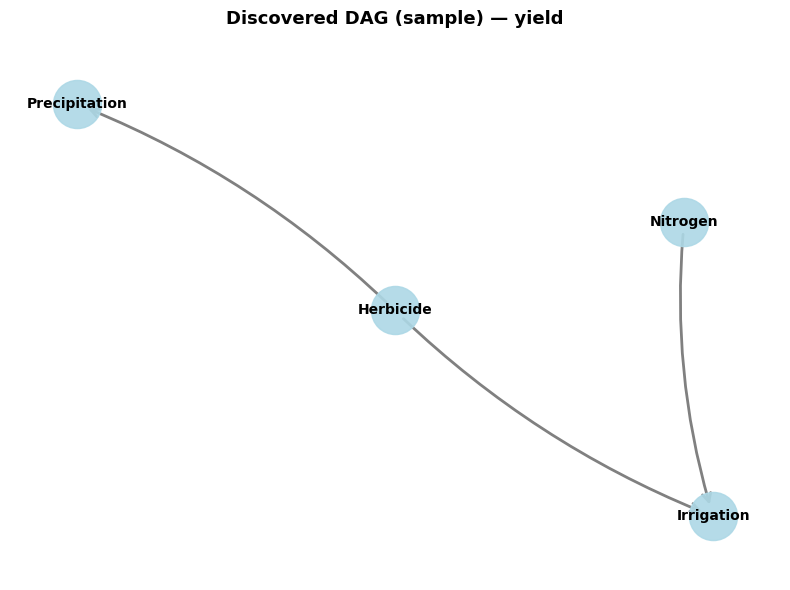

In [12]:
run_integrated_on_numpy_bundle(
    "../../datasets/yield_preprocessed.npz",
    dataset_name="yield",
    task_type=None,
    seed=100
)


Integrated Causal Discovery + ASV on: ../datasets/lung_cancer_risk.csv

Training model...
✓ Model: R2=0.7217, MAE=1.4968

------------------------------------------------------------------------
Step 1: Causal discovery (PC)
------------------------------------------------------------------------
Running PC on 3 features (alpha=0.1)...
✓ PC completed -> CPDAG
✓ Sampled 5 DAG(s) from CPDAG
✓ Saved 'outputs/causal_graph_sample_lung_cancer_risk.png'

Initializing on-manifold imputer...

Evaluating ASV on 50 test points...
  Processing point 1/50
  Processing point 11/50
  Processing point 21/50
  Processing point 31/50
  Processing point 41/50

Efficiency verification (mean |sum(phi) - (vN - v0)|):
  Mean gap (ASV): 0.000000
Saved: outputs/lung_cancer_risk_global_asv_onmanifold_causal.csv
Saved: outputs/lung_cancer_risk_asv_onmanifold_causal.png

Top features (ASV on-manifold, causal):
  drink_coffee              -0.075302 ± 0.598033
  smoking                   -0.157875 ± 2.644461
  str

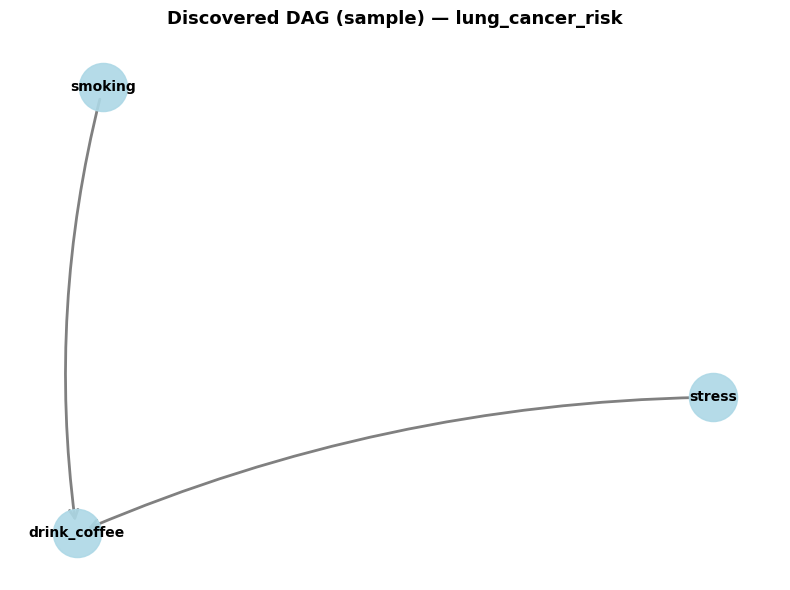

In [16]:
CSV_PATH = "../../datasets/lung_cancer_risk.csv"
TARGET_HINT = "lung_cancer_risk"  # or None

run_integrated_on_csv(
    CSV_PATH,
    dataset_name="lung_cancer_risk",   # or None for auto name
    target_hint=TARGET_HINT,
    seed=100
)


Integrated Causal Discovery + ASV on: ../datasets/cv_risk.csv

Training model...
✓ Model: R2=0.6618, MAE=1.3510

------------------------------------------------------------------------
Step 1: Causal discovery (PC)
------------------------------------------------------------------------
Running PC on 4 features (alpha=0.1)...
✓ PC completed -> CPDAG
✓ Sampled 5 DAG(s) from CPDAG
✓ Saved 'outputs/causal_graph_sample_cv_risk.png'

Initializing on-manifold imputer...

Evaluating ASV on 50 test points...
  Processing point 1/50
  Processing point 11/50
  Processing point 21/50
  Processing point 31/50
  Processing point 41/50

Efficiency verification (mean |sum(phi) - (vN - v0)|):
  Mean gap (ASV): 0.000000
Saved: outputs/cv_risk_global_asv_onmanifold_causal.csv
Saved: outputs/cv_risk_asv_onmanifold_causal.png

Top features (ASV on-manifold, causal):
  diet_score                +0.082961 ± 1.358213
  bmi                       -0.003653 ± 1.448700
  sleep_duration            -0.036013 ± 0

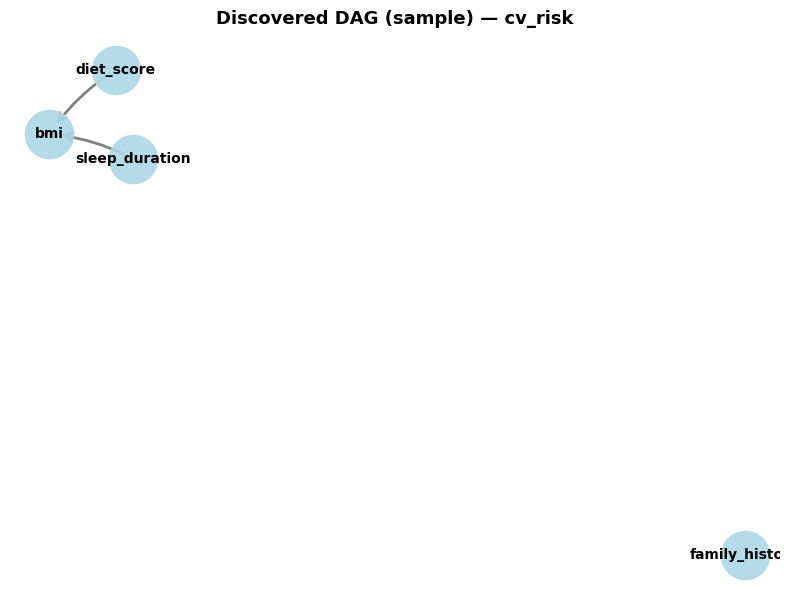

In [ ]:
CSV_PATH = "../../datasets/cv_risk.csv"
TARGET_HINT = "cv_risk"  # or None

run_integrated_on_csv(
    CSV_PATH,
    dataset_name="cv_risk",   # or None for auto name
    target_hint=TARGET_HINT,
    seed=100
)


Integrated Causal Discovery + ASV on: ../datasets/Crop_recommendation.csv
Label mapping: {0: 'rice', 1: 'maize', 2: 'chickpea', 3: 'kidneybeans', 4: 'pigeonpeas', 5: 'mothbeans', 6: 'mungbean', 7: 'blackgram', 8: 'lentil', 9: 'pomegranate', 10: 'banana', 11: 'mango', 12: 'grapes', 13: 'watermelon', 14: 'muskmelon', 15: 'apple', 16: 'orange', 17: 'papaya', 18: 'coconut', 19: 'cotton', 20: 'jute', 21: 'coffee'}

Training model...
✓ Model: acc=0.9964, macroF1=0.9964

------------------------------------------------------------------------
Step 1: Causal discovery (PC)
------------------------------------------------------------------------
Running PC on 7 features (alpha=0.1)...
✓ PC completed -> CPDAG
✓ Sampled 5 DAG(s) from CPDAG
✓ Saved 'outputs/causal_graph_sample_Crop_recommendation.png'

Initializing on-manifold imputer...

Evaluating ASV on 50 test points...
  Processing point 1/50
  Processing point 11/50
  Processing point 21/50
  Processing point 31/50
  Processing point 41/50


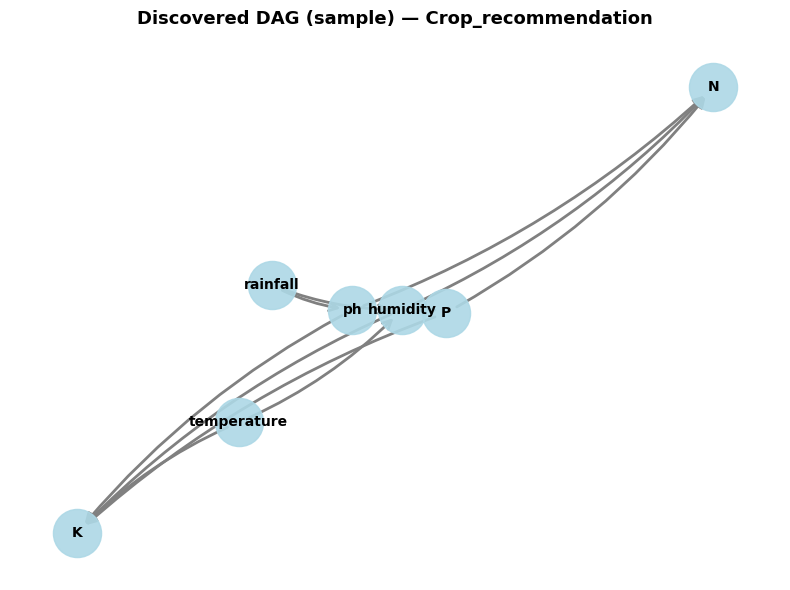

In [21]:
CSV_PATH = "../../datasets/Crop_recommendation.csv"
TARGET_HINT = "label"  # or None

run_integrated_on_csv(
    CSV_PATH,
    dataset_name="Crop_recommendation",   # or None for auto name
    target_hint=TARGET_HINT,
    seed=100
)